# Avaliação estatística do RAG do EstudaAI

**Pergunta:** qual método de busca o app deve usar para encontrar, nas aulas do estudante, o trecho que responde à pergunta dele? E dá para saber quando a resposta **não está** nas aulas, para a IA não inventar?

O EstudaAI responde dúvidas com RAG: busca os 5 trechos mais relevantes das anotações e manda para o LLM, que só pode usá-los e precisa citar as fontes. Se a busca falhar, a resposta falha, por melhor que seja o modelo. Por isso a recuperação é avaliada separadamente.

**Resumo dos resultados** (109 perguntas com resposta, IC de 95% por bootstrap):

| Método | Hit@1 | Hit@5 [IC 95%] | Hit@5 em paráfrases | MRR |
|---|---:|---:|---:|---:|
| BM25 (padrão atual do app) | 70% | 76% [68–84%] | 53% | 0,72 |
| Embeddings | 75% | **97%** [94–100%] | **95%** | 0,85 |
| Híbrida (RRF) | **78%** | 95% [90–98%] | 89% | **0,86** |

1. Embeddings e híbrida são **significativamente melhores** que o BM25 (McNemar exato, p < 0,0001 após correção de Holm). Toda a diferença está nas **paráfrases**: nas perguntas literais os três acertam 100% no top 5. O motivo é vocabulário: **45% das paráfrases não têm nenhuma palavra em comum** com o trecho certo.
2. Embeddings × híbrida **não** tem diferença significativa (p = 0,5). A híbrida acerta mais a 1ª posição; os embeddings, mais o top 5.
3. Uma pergunta **sem resposta** nas aulas pode ser detectada pelo score do melhor trecho (AUC ≈ 0,83), o que permite o app dizer "não encontrei nas suas aulas" em vez de deixar o LLM inventar.
4. Ajustar os parâmetros do BM25 (k1, b) quase não muda nada (MRR entre 0,718 e 0,724): o problema dele é de **vocabulário**, não de calibração.

**Recomendação para o app:** usar a busca **híbrida** como padrão quando o modelo de embeddings estiver carregado (melhor 1º resultado e 95% de top 5), com BM25 como plano B offline, e responder "não encontrei" quando o melhor trecho tiver similaridade abaixo de ~0,41.

## 1. Dados

- **Corpus:** 18 aulas de 9 matérias (Biologia, Química, História, Física, Matemática, Geografia, Português, Sociologia), no mesmo formato das anotações do app (tópicos com `# título`). Arquivo: `eval/dados/corpus.json`.
- **Perguntas:** 127, de três tipos (`eval/dados/perguntas.csv`):
  - **literal**: usa as palavras da aula ("Quais são as fases da mitose?");
  - **paráfrase**: mesma ideia com outras palavras, como um estudante perguntaria ("Como uma célula vira duas iguais?");
  - **sem resposta**: assunto que não está em nenhuma aula, incluindo algumas parecidas com o conteúdo ("O que foi a Revolução Russa?").
- **Gabarito:** a aula e um trecho que precisa aparecer no resultado. Quando a resposta existe em mais de um lugar (ex.: "êxodo rural" aparece em História e em Geografia), todos os lugares valem.
- **Embeddings:** gerados pelo **próprio app** (Transformers.js, modelo `paraphrase-multilingual-MiniLM-L12-v2` quantizado) com `analise/exportar_embeddings.html`, para medir exatamente o modelo que o estudante usa.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from rag_eval import *

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
CORES = {"BM25": "#9aa9c7", "Embeddings": "#1e6bff", "Híbrida": "#ffb020"}
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)

pastas = carregar_corpus()
perguntas = carregar_perguntas()
vetores = carregar_vetores()
chunks = build_chunks(pastas)            # mesmo chunking do app
respondiveis = [p for p in perguntas if p.respondivel]

# Sanidade: todo gabarito precisa existir em algum trecho
assert all(any(relevante(c, p) for c in chunks) for p in respondiveis)

df_p = pd.DataFrame({"tipo": [p.tipo for p in perguntas],
                     "materia": [next((pa["nome"] for pa in pastas for a in pa["aulas"] if p.gabarito and a["id"] == p.gabarito[0][0]), "—") for p in perguntas]})
print(f"{sum(len(p['aulas']) for p in pastas)} aulas, {len(chunks)} trechos, {len(perguntas)} perguntas")
pd.crosstab(df_p.materia, df_p.tipo, margins=True, margins_name="total")

18 aulas, 49 trechos, 127 perguntas


tipo,literal,parafrase,sem_resposta,total
materia,,,,
Biologia,9,11,0,20
Física,6,9,0,15
Geografia,7,6,0,13
História,8,9,0,17
Matemática,8,6,0,14
Português,4,3,0,7
Química,9,8,0,17
Sociologia,3,3,0,6
—,0,0,18,18


### Reprodutibilidade: o Python mede o mesmo que o app?

`rag_eval.py` é uma porta do BM25 e do chunking do app (`src/rag/search.js`). Antes de qualquer conclusão, conferimos que, nas 30 perguntas originais (as mesmas dos testes automatizados do app), os números batem com os do app: **Hit@5 = 83,3% e MRR = 0,784**.

In [2]:
ids_originais = {"bio-divisao", "bio-foto", "qui-ligacoes", "qui-ph", "his-industrial", "his-francesa", "fis-newton", "fis-energia"}
pastas8 = [{"nome": p["nome"], "aulas": [a for a in p["aulas"] if a["id"] in ids_originais]} for p in pastas]
chunks8 = build_chunks(pastas8)
bm8 = BM25(chunks8)
r8 = np.array([posicao(bm8.search(p.pergunta, 5), chunks8, p) or np.nan for p in perguntas if p.id <= 30], dtype=float)
print(f"Hit@5 = {hit_at(r8, 5).mean():.4f} | MRR = {reciprocal(r8).mean():.4f}   (app: 0.8333 | 0.7844)")

Hit@5 = 0.8333 | MRR = 0.7844   (app: 0.8333 | 0.7844)


## 2. Por que a busca por palavras falha? Sobreposição de vocabulário

Hipótese: o BM25 depende de palavras em comum entre a pergunta e o trecho. Medimos a **sobreposição de Jaccard** entre as palavras da pergunta e as do trecho correto (depois de tirar acentos e stopwords).

           count   mean    50%
tipo                          
literal     54.0  0.173  0.160
parafrase   55.0  0.051  0.043
Paráfrases sem NENHUMA palavra em comum com o trecho certo: 45%


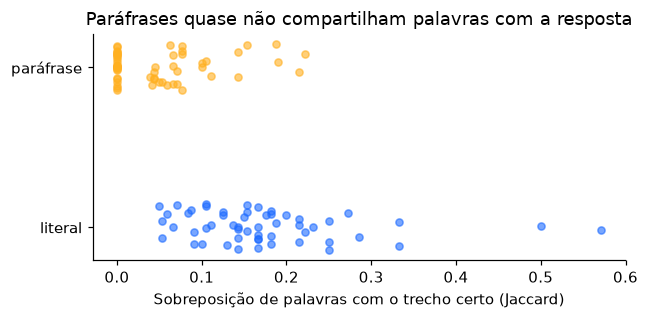

In [3]:
def jaccard(a, b):
    a, b = set(tokenize(a)), set(tokenize(b))
    return len(a & b) / len(a | b) if a | b else 0

sobre = pd.DataFrame([{"tipo": p.tipo, "jaccard": max(jaccard(p.pergunta, c.text + " " + c.lesson) for c in chunks if relevante(c, p))}
                      for p in respondiveis])
print(sobre.groupby("tipo").jaccard.describe()[["count", "mean", "50%"]].round(3))
print("Paráfrases sem NENHUMA palavra em comum com o trecho certo:",
      f"{(sobre[sobre.tipo == 'parafrase'].jaccard == 0).mean():.0%}")

fig, ax = plt.subplots(figsize=(6, 3))
for i, (tipo, g) in enumerate(sobre.groupby("tipo")):
    ax.scatter(g.jaccard, np.full(len(g), i) + np.random.default_rng(1).uniform(-.15, .15, len(g)), alpha=.6,
               color=["#1e6bff", "#ffb020"][i], s=22)
ax.set_yticks([0, 1], ["literal", "paráfrase"]); ax.set_xlabel("Sobreposição de palavras com o trecho certo (Jaccard)")
ax.set_title("Paráfrases quase não compartilham palavras com a resposta")
fig.tight_layout(); fig.savefig(FIG / "sobreposicao.png"); plt.show()

## 3. Comparação dos métodos

Métricas: **Hit@k** = fração das perguntas em que o trecho certo veio entre os *k* primeiros; **MRR** = média de 1/posição do trecho certo (0 se não veio no top 10). O app manda 5 trechos ao LLM, então **Hit@5** é a chance de o LLM receber a resposta. Intervalos de confiança de 95% por **bootstrap** (10.000 reamostragens das perguntas).

Também testamos uma correção de um bug encontrado na porta: a lista de stopwords do app tem palavras acentuadas ("são", "também"), mas o texto é comparado **sem** acento, então elas nunca eram removidas.

In [4]:
bm = BM25(chunks)
bm_corr = BM25(chunks, stopwords=STOPWORDS_CORRIGIDAS)
emb = Embeddings(chunks, vetores)
hib = Hibrida(bm, emb)
METODOS = {"BM25": bm, "BM25 (stopwords corrigidas)": bm_corr, "Embeddings": emb, "Híbrida": hib}

def ranks(metodo, ps=respondiveis, ch=chunks, k=10):
    return np.array([posicao(metodo.search(p.pergunta, k), ch, p) or np.nan for p in ps], dtype=float)

R = {nome: ranks(m) for nome, m in METODOS.items()}
tipos = np.array([p.tipo for p in respondiveis])

linhas = []
for nome, r in R.items():
    for grupo, mask in [("todas", tipos != ""), ("literal", tipos == "literal"), ("paráfrase", tipos == "parafrase")]:
        h5, lo, hi = bootstrap_ci(hit_at(r[mask], 5))
        mrr, mlo, mhi = bootstrap_ci(reciprocal(r[mask]))
        linhas.append({"método": nome, "perguntas": grupo, "n": int(mask.sum()), "Hit@1": hit_at(r[mask], 1).mean(),
                       "Hit@5": h5, "IC Hit@5": f"[{lo:.0%}, {hi:.0%}]", "MRR": mrr, "IC MRR": f"[{mlo:.2f}, {mhi:.2f}]"})
tabela = pd.DataFrame(linhas)
tabela.style.format({"Hit@1": "{:.0%}", "Hit@5": "{:.0%}", "MRR": "{:.3f}"}).hide(axis="index")

método,perguntas,n,Hit@1,Hit@5,IC Hit@5,MRR,IC MRR
BM25,todas,109,70%,76%,"[68%, 83%]",0.724,"[0.64, 0.80]"
BM25,literal,54,100%,100%,"[100%, 100%]",1.000,"[1.00, 1.00]"
BM25,paráfrase,55,40%,53%,"[40%, 65%]",0.452,"[0.33, 0.58]"
BM25 (stopwords corrigidas),todas,109,70%,76%,"[68%, 83%]",0.724,"[0.64, 0.80]"
BM25 (stopwords corrigidas),literal,54,100%,100%,"[100%, 100%]",1.000,"[1.00, 1.00]"
BM25 (stopwords corrigidas),paráfrase,55,40%,53%,"[40%, 65%]",0.452,"[0.33, 0.58]"
Embeddings,todas,109,75%,97%,"[94%, 100%]",0.847,"[0.79, 0.90]"
Embeddings,literal,54,85%,100%,"[100%, 100%]",0.915,"[0.86, 0.97]"
Embeddings,paráfrase,55,65%,95%,"[87%, 100%]",0.779,"[0.69, 0.86]"
Híbrida,todas,109,78%,94%,"[90%, 98%]",0.859,"[0.81, 0.91]"


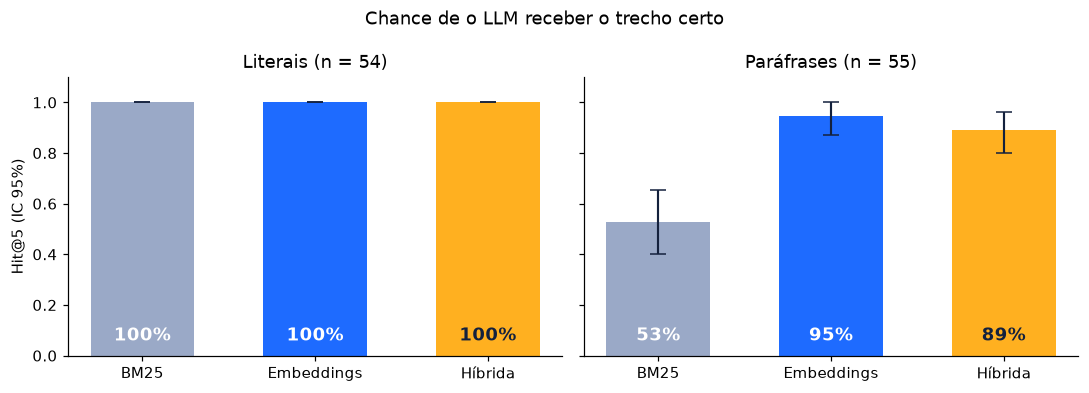

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, grupo, mask in [(axes[0], "Literais", tipos == "literal"), (axes[1], "Paráfrases", tipos == "parafrase")]:
    for i, nome in enumerate(["BM25", "Embeddings", "Híbrida"]):
        m, lo, hi = bootstrap_ci(hit_at(R[nome][mask], 5))
        ax.bar(i, m, color=CORES[nome], width=.6)
        ax.errorbar(i, m, yerr=[[m - lo], [hi - m]], color="#14213d", capsize=5, lw=1.4)
        ax.text(i, .06, f"{m:.0%}", ha="center", fontweight="bold", color="white" if nome != "Híbrida" else "#14213d", fontsize=12)
    ax.set_xticks(range(3), ["BM25", "Embeddings", "Híbrida"]); ax.set_title(f"{grupo} (n = {mask.sum()})"); ax.set_ylim(0, 1.1)
axes[0].set_ylabel("Hit@5 (IC 95%)")
fig.suptitle("Chance de o LLM receber o trecho certo")
fig.tight_layout(); fig.savefig(FIG / "hit5_por_tipo.png"); plt.show()

### Teste estatístico pareado

As perguntas são as mesmas para todos os métodos, então comparamos **pareado**:
- **Hit@5** (acertou ou não): **McNemar exato**, que só olha as perguntas em que um método acertou e o outro não;
- **MRR**: **teste de permutação** pareado (troca aleatória de sinais, 20.000 vezes).

Como são várias comparações, os p-valores são corrigidos por **Holm-Bonferroni**.

In [6]:
pares = [("Embeddings", "BM25"), ("Híbrida", "BM25"), ("Embeddings", "Híbrida"), ("BM25 (stopwords corrigidas)", "BM25")]
res = []
for a, b in pares:
    so_a, so_b, p_mc = mcnemar_exato(hit_at(R[a], 5), hit_at(R[b], 5))
    d, p_perm = permutacao_pareada(reciprocal(R[a]), reciprocal(R[b]))
    res.append({"A × B": f"{a} × {b}", "só A acerta": so_a, "só B acerta": so_b, "p McNemar": p_mc, "Δ MRR (A−B)": d, "p permutação": p_perm})
res = pd.DataFrame(res)
res["p McNemar (Holm)"] = holm(list(res["p McNemar"]))
res["p permutação (Holm)"] = holm(list(res["p permutação"]))
res.style.format({c: "{:.4f}" for c in res.columns if c.startswith("p")} | {"Δ MRR (A−B)": "{:+.3f}"}).hide(axis="index")

A × B,só A acerta,só B acerta,p McNemar,Δ MRR (A−B),p permutação,p McNemar (Holm),p permutação (Holm)
Embeddings × BM25,23,0,0.0000,+0.123,0.0067,0.0000,0.0201
Híbrida × BM25,20,0,0.0000,+0.135,0.0000,0.0000,0.0000
Embeddings × Híbrida,3,0,0.2500,-0.012,0.6759,0.5000,1.0000
BM25 (stopwords corrigidas) × BM25,0,0,1.0000,+0.000,1.0000,1.0000,1.0000


**Leitura:**
- Embeddings e híbrida ganham do BM25 em **20 a 23 perguntas** e não perdem em nenhuma: diferença significativa.
- Embeddings × híbrida: só 3 perguntas de diferença, **não significativo**. Com este conjunto, os dois são equivalentes no top 5.
- O bug das stopwords **não teve efeito medido**: as palavras acentuadas da lista quase não aparecem nas perguntas e trechos. Vale corrigir por correção, não por desempenho.

## 4. Experimentos de projeto

### 4.1 Quantos trechos mandar ao LLM? (curva Hit@k)

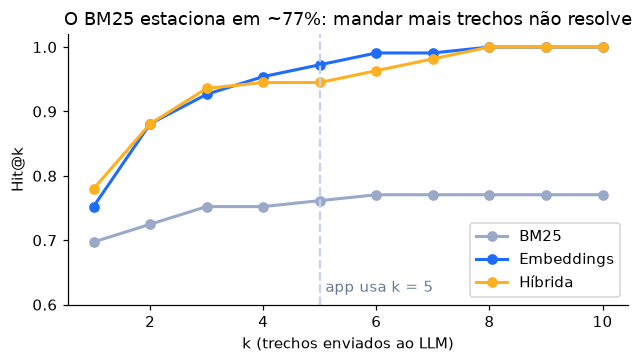

In [7]:
ks = range(1, 11)
fig, ax = plt.subplots(figsize=(6, 3.4))
for nome in ["BM25", "Embeddings", "Híbrida"]:
    ax.plot(ks, [hit_at(R[nome], k).mean() for k in ks], marker="o", color=CORES[nome], label=nome, lw=2)
ax.axvline(5, color="#c4d3ee", ls="--"); ax.text(5.1, .62, "app usa k = 5", color="#66789a")
ax.set_xlabel("k (trechos enviados ao LLM)"); ax.set_ylabel("Hit@k"); ax.set_ylim(.6, 1.02); ax.legend()
ax.set_title("O BM25 estaciona em ~77%: mandar mais trechos não resolve")
fig.tight_layout(); fig.savefig(FIG / "curva_k.png"); plt.show()

### 4.2 Tamanho do trecho: aula inteira, tópico ou frase?

Trechos maiores contêm a resposta com mais frequência, mas mandam **mais texto ao LLM** (custo, latência e mais chance de distração). Medimos o Hit@5 e o tamanho médio do contexto (caracteres dos 5 trechos).

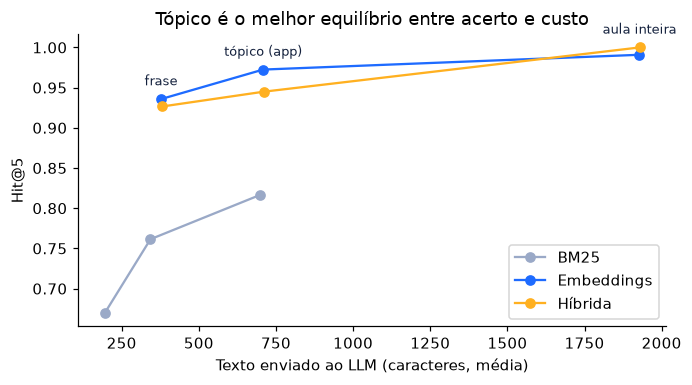

granularidade,trechos,método,Hit@5,MRR,contexto (caracteres)
aula inteira,18,BM25,81.7%,0.781,698
aula inteira,18,Embeddings,99.1%,0.896,1925
aula inteira,18,Híbrida,100.0%,0.899,1929
tópico (app),49,BM25,76.1%,0.724,343
tópico (app),49,Embeddings,97.2%,0.847,709
tópico (app),49,Híbrida,94.5%,0.859,710
frase,78,BM25,67.0%,0.614,195
frase,78,Embeddings,93.6%,0.787,378
frase,78,Híbrida,92.7%,0.780,382


In [8]:
gran = []
for modo, nome_modo in [("aula", "aula inteira"), ("secao", "tópico (app)"), ("frase", "frase")]:
    ch = build_chunks(pastas, modo)
    b, e = BM25(ch), Embeddings(ch, vetores)
    for nome, m in [("BM25", b), ("Embeddings", e), ("Híbrida", Hibrida(b, e))]:
        r = ranks(m, ch=ch)
        contexto = np.mean([sum(len(ch[i].text) for i in m.search(p.pergunta, 5)) for p in respondiveis])
        gran.append({"granularidade": nome_modo, "trechos": len(ch), "método": nome,
                     "Hit@5": hit_at(r, 5).mean(), "MRR": reciprocal(r).mean(), "contexto (caracteres)": contexto})
gran = pd.DataFrame(gran)

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for nome, g in gran.groupby("método"):
    ax.plot(g["contexto (caracteres)"], g["Hit@5"], marker="o", color=CORES[nome], label=nome, lw=1.5)
# rótulos só uma vez por granularidade, acima do ponto mais alto
for modo, g in gran.groupby("granularidade"):
    topo = g.loc[g["Hit@5"].idxmax()]
    ax.annotate(modo, (topo["contexto (caracteres)"], topo["Hit@5"]), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color="#14213d")
ax.set_xlabel("Texto enviado ao LLM (caracteres, média)"); ax.set_ylabel("Hit@5"); ax.legend(loc="lower right")
ax.set_title("Tópico é o melhor equilíbrio entre acerto e custo")
fig.tight_layout(); fig.savefig(FIG / "granularidade.png"); plt.show()
gran.style.format({"Hit@5": "{:.1%}", "MRR": "{:.3f}", "contexto (caracteres)": "{:.0f}"}).hide(axis="index")

A aula inteira chega a 99–100% de Hit@5, mas manda **2,7× mais texto** que o tópico, por 2 a 3 pontos a mais. A frase é pequena demais: corta o contexto e piora todos os métodos. O tópico, que o app já usa, é o melhor equilíbrio.

### 4.3 Vale a pena ajustar o BM25?

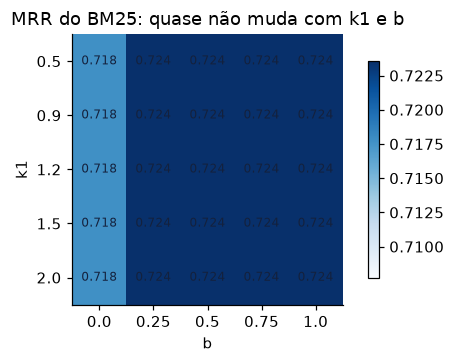

MRR varia só entre 0.718 e 0.724 (app: k1=1.2, b=0.75 → 0.724)


In [9]:
k1s, bs = [0.5, 0.9, 1.2, 1.5, 2.0], [0.0, 0.25, 0.5, 0.75, 1.0]
grade = np.array([[reciprocal(ranks(BM25(chunks, k1, b))).mean() for b in bs] for k1 in k1s])
fig, ax = plt.subplots(figsize=(5, 3.4))
im = ax.imshow(grade, cmap="Blues", vmin=grade.min() - .01, vmax=grade.max())
ax.set_xticks(range(len(bs)), bs); ax.set_yticks(range(len(k1s)), k1s); ax.set_xlabel("b"); ax.set_ylabel("k1")
for i in range(len(k1s)):
    for j in range(len(bs)):
        ax.text(j, i, f"{grade[i, j]:.3f}", ha="center", va="center", fontsize=8, color="#14213d")
ax.set_title("MRR do BM25: quase não muda com k1 e b")
fig.colorbar(im, ax=ax, shrink=.8); fig.tight_layout(); fig.savefig(FIG / "grade_bm25.png"); plt.show()
print(f"MRR varia só entre {grade.min():.3f} e {grade.max():.3f} (app: k1=1.2, b=0.75 → {grade[2, 3]:.3f})")

In [10]:
c_rrf = pd.DataFrame([{"c": c, "Hit@5": hit_at(ranks(Hibrida(bm, emb, c)), 5).mean(), "MRR": reciprocal(ranks(Hibrida(bm, emb, c))).mean()}
                      for c in [1, 10, 30, 60, 100]])
c_rrf.style.format({"Hit@5": "{:.1%}", "MRR": "{:.3f}"}).hide(axis="index")

c,Hit@5,MRR
1,95.4%,0.861
10,94.5%,0.859
30,94.5%,0.859
60,94.5%,0.859
100,94.5%,0.859


O parâmetro *c* da fusão RRF também quase não importa (o valor padrão da literatura, 60, é usado no app).

## 5. Saber quando NÃO há resposta

Se a pergunta não está nas aulas, o ideal é o app avisar em vez de mandar trechos irrelevantes ao LLM. Usamos o **score do melhor trecho** como classificador: score baixo ⇒ "sem resposta". Avaliamos com a curva ROC nas 127 perguntas (18 sem resposta).

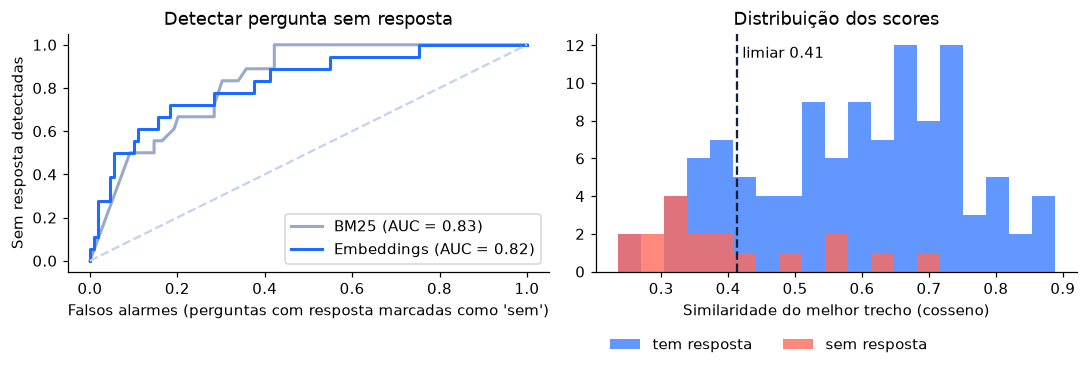

Limiar (Youden) = 0.414: detecta 72% das perguntas sem resposta, com 18% de falsos alarmes
BM25 dá score zero (nenhuma palavra em comum) para 9 das 18 perguntas sem resposta


In [11]:
y = np.array([0 if p.respondivel else 1 for p in perguntas])
top_bm = np.array([bm.scores(p.pergunta).max() for p in perguntas])
top_emb = np.array([emb.scores(p.pergunta).max() for p in perguntas])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for nome, s in [("BM25", top_bm), ("Embeddings", top_emb)]:
    fpr, tpr, _ = roc_curve(y, -s)
    axes[0].plot(fpr, tpr, color=CORES[nome], lw=2, label=f"{nome} (AUC = {roc_auc_score(y, -s):.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="#c4d3ee"); axes[0].legend(loc="lower right")
axes[0].set_xlabel("Falsos alarmes (perguntas com resposta marcadas como 'sem')"); axes[0].set_ylabel("Sem resposta detectadas")
axes[0].set_title("Detectar pergunta sem resposta")

fpr, tpr, thr = roc_curve(y, -top_emb); j = np.argmax(tpr - fpr); limiar = -thr[j]
bins = np.linspace(top_emb.min(), top_emb.max(), 20)
axes[1].hist(top_emb[y == 0], bins, alpha=.7, color=CORES["Embeddings"], label="tem resposta")
axes[1].hist(top_emb[y == 1], bins, alpha=.8, color="#ff6b5b", label="sem resposta")
axes[1].axvline(limiar, color="#14213d", ls="--"); axes[1].text(limiar, axes[1].get_ylim()[1] * .9, f" limiar {limiar:.2f}")
axes[1].set_xlabel("Similaridade do melhor trecho (cosseno)"); axes[1].legend(loc="upper left", bbox_to_anchor=(0, -.22), ncol=2, frameon=False)
axes[1].set_title("Distribuição dos scores")
fig.tight_layout(); fig.savefig(FIG / "sem_resposta.png"); plt.show()

print(f"Limiar (Youden) = {limiar:.3f}: detecta {tpr[j]:.0%} das perguntas sem resposta, com {fpr[j]:.0%} de falsos alarmes")
print(f"BM25 dá score zero (nenhuma palavra em comum) para {(top_bm[y == 1] == 0).sum()} das {y.sum()} perguntas sem resposta")

Com AUC ≈ 0,83, o score separa razoavelmente bem as perguntas sem resposta. Um limiar de similaridade ~0,41 pegaria cerca de 7 em cada 10 perguntas sem resposta, errando em ~18% das que têm. É um bom **filtro de segurança** antes do LLM: abaixo do limiar, o app responde "não encontrei isso nas suas aulas" e oferece pesquisar no Google.

## 6. Análise de erros

In [12]:
erros = pd.DataFrame([{"id": p.id, "pergunta": p.pergunta,
                       **{nome: ("✔" if (not np.isnan(R[nome][i]) and R[nome][i] <= 5) else "✘") for nome in ["BM25", "Embeddings", "Híbrida"]}}
                      for i, p in enumerate(respondiveis)])
falhas = erros[(erros[["BM25", "Embeddings", "Híbrida"]] == "✘").any(axis=1)]
print(f"{len(falhas)} perguntas em que algum método falhou (todas paráfrases: {all(p.tipo == 'parafrase' for p in respondiveis if p.id in set(falhas.id))})")
falhas[(falhas.Embeddings == "✘") | (falhas.Híbrida == "✘")].style.hide(axis="index")

26 perguntas em que algum método falhou (todas paráfrases: True)


id,pergunta,BM25,Embeddings,Híbrida
28,O que acontece quando empurro uma parede?,✘,✔,✘
36,Por que pais de olhos castanhos podem ter um filho de olhos claros?,✘,✘,✘
63,Onde o gráfico corta o eixo horizontal?,✘,✘,✘
82,Por que há cada vez mais idosos no Brasil?,✘,✔,✘
84,Por que tanta gente se mudou para São Paulo e Rio?,✘,✔,✘
90,"Quando alguém fala 'que dia lindo' debaixo de chuva, que recurso está usando?",✘,✘,✘


Os erros que sobram nos melhores métodos têm padrão:
- **Raciocínio, não vocabulário:** "Por que pais de olhos castanhos podem ter um filho de olhos claros?" exige ligar o exemplo (olhos) ao conceito (alelo recessivo em dose dupla). Nenhuma busca por similaridade faz isso sozinha.
- **Exemplos fora do texto:** "Quando alguém fala 'que dia lindo' debaixo de chuva…" descreve uma situação de ironia sem citar a palavra.
- **Na híbrida**, o BM25 às vezes "puxa" para cima um trecho com palavras em comum, mas errado (ex.: "empurro uma parede" → trechos de Física com "força").

Possíveis melhorias: reescrever a pergunta com o LLM antes de buscar (*query rewriting* / HyDE) e um reranker *cross-encoder* nos 10 primeiros.

## 7. Limitações

- **Conjunto pequeno, escrito por quem desenvolveu o app** (127 perguntas): pode haver viés a favor de quem conhece o texto. Mitigação: paráfrases escritas para evitar as palavras da aula, perguntas sem resposta "parecidas" e gabarito com múltiplas respostas válidas. O próximo passo é coletar perguntas reais de estudantes.
- **Corpus sintético e limpo:** anotações reais têm erros de digitação e texto de OCR, o que tende a prejudicar mais o BM25.
- **Só a recuperação foi avaliada.** A qualidade da resposta do LLM (fidelidade às fontes, citação correta) precisa de outra avaliação, por exemplo com um LLM como juiz.
- **Embeddings quantizados:** os vetores são os do app (modelo quantizado no navegador), que pode diferir levemente do modelo completo. Isso é intencional: mede o que o estudante usa.

## 8. Como reproduzir

```bash
python -m venv .venv && .venv\Scripts\activate      # Windows (Linux/macOS: source .venv/bin/activate)
pip install -r analise/requirements.txt
jupyter nbconvert --to notebook --execute --inplace analise/analise_rag.ipynb
```

Para gerar de novo os embeddings (só se mudar o corpus ou as perguntas): `python analise/servidor_export.py` e abrir `http://localhost:8090/analise/exportar_embeddings.html`.